# Exchange audit

Reads the cells `build_audit.py` writes to `logs/audit/<topic>_<model>/<phase>_<sub>/`
([`../schedule.md`](../schedule.md) § Exchange audit). Descriptive: every reading per cell, drawn
where a figure reads better than a table, nothing tested. § 2–9 are the schedule's *Reported per cell*, § 10 its decision, § 11 the sample sizes behind them. The calibration, under `logs/audit/calibration/`, is read by
[`calibration_analysis.ipynb`](calibration_analysis.ipynb). `AUDIT_LOGS` points it at another tree, e.g. a stub run's.

## 1. Load

In [69]:
import os
import sys
from pathlib import Path

from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)  # every table at three decimals

CWD = Path.cwd().resolve()
REPO = next(p for p in [CWD, *CWD.parents] if (p / "simulation" / "config.py").is_file())
sys.path.insert(0, str(REPO / "analysis"))
import fit  # noqa: E402
import metrics  # noqa: E402
import config  # noqa: E402  (fit puts simulation/ on the path)

from collections import Counter

LOGS = Path(os.getenv("AUDIT_LOGS", REPO / "analysis" / "logs" / "audit"))
TOPICS = ("nuclear", "renewables", "coffee_tea")
MODELS = ("qwen3.5-nodraft:4b", "gemma4-nodraft:e4b", "granite4.2-nodraft:3b")
SUBS = ("meetings", "windows")
CONDITIONS = ("full", "own")

cells = {f"{t}_{m.replace(':', '-')}": LOGS / f"{t}_{m.replace(':', '-')}"
         for m in MODELS for t in TOPICS}
cells = {c: d for c, d in cells.items() if any(d.glob("audit_*"))}
units = {c: {s: metrics.audit_units(d, s) for s in SUBS} for c, d in cells.items()}


def events(cell_dir, kinds):
    """Every event of the given types, over the cell's sub-phases."""
    return [ev for sub in sorted(cell_dir.glob("*_*")) if (sub / "events.jsonl").is_file()
            for ev in metrics.read_events(sub) if ev["type"] in kinds]


def meetings(c):
    return units[c]["meetings"]


def calls(c):
    """Every position call of a cell's units: declaration, probe or self-read; ``one_entry``
    marks a meeting's declaration after its exchange (not empty-memory, not a window)."""
    rows = []
    for u in meetings(c) + units[c]["windows"]:
        for path, call in metrics.position_calls(u):
            kind = path.rsplit("/", 1)[-1]
            rows.append({"kind": kind if kind in ("probe", "self_read") else "declaration",
                         "one_entry": u["kind"] == "meeting" and kind in CONDITIONS,
                         "x": call["x"], "topic_first": call["topic_first"]})
    return pd.DataFrame(rows, columns=["kind", "one_entry", "x", "topic_first"])


def row_shares(index, columns):
    """P(column | row), with the row's n."""
    return (pd.crosstab(index, columns, normalize="index").round(3)
            .assign(n=pd.crosstab(index, columns).sum(axis=1)))


print(f"{len(cells)} of {len(TOPICS) * len(MODELS)} cells under {LOGS}")
for c in cells:
    print(c, {s: Counter(u["kind"] for u in us) for s, us in units[c].items()})

9 of 9 cells under C:\Users\jonas\OneDrive\Dokumente\Studium\Inhaltliches\Master\Thesis\thesis\analysis\logs\audit
nuclear_qwen3.5-nodraft-4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
renewables_qwen3.5-nodraft-4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
coffee_tea_qwen3.5-nodraft-4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
nuclear_gemma4-nodraft-e4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
renewables_gemma4-nodraft-e4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
coffee_tea_gemma4-nodraft-e4b {'meetings': Counter({'meeting': 800}), 'windows': Counter({'order': 6160, 'serial': 3474, 'settled': 770})}
nuclear_granite4.2-nodraft-3b {'meetings': Counter({'meet

In [70]:
# Figures: one panel per cell, topics down, models across. Positions keep their colours
# throughout: red −, blue +; the conditions theirs.
POSITION_LABEL = {-1: "−1", 1: "+1"}
POSITION_COLOR = {-1: "#b92f2e", 1: "#1c5cab"}
COND_COLOR = {"full": "#0d366b", "own": "#898781"}
SHARE = LinearSegmentedColormap.from_list("share", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
SHIFT = LinearSegmentedColormap.from_list("shift", ["#b92f2e", "#f0efec", "#1c5cab"])


def cell_label(c):
    topic, model = c.rsplit("_", 1)
    return f"{model.split('-nodraft')[0]} × {topic}"


def panels(**kw):
    """A figure of TOPICS × MODELS panels and its (cell, axes) pairs; a cell without data stays blank."""
    fig, axes = plt.subplots(len(TOPICS), len(MODELS), layout="constrained", squeeze=False, **kw)
    pairs = []
    for row, t in zip(axes, TOPICS):
        for ax, m in zip(row, MODELS):
            c = f"{t}_{m.replace(':', '-')}"
            if c in cells:
                ax.set_title(cell_label(c), fontsize=10)
                pairs.append((c, ax))
            else:
                ax.axis("off")
    return fig, pairs


def annotate(ax, table, cmap, norm, keep, fmt):
    """Print the cells ``keep`` selects, in the ink their fill needs."""
    for i, row in enumerate(table.to_numpy()):
        for j, v in enumerate(row):
            if keep(v):
                r, g, b, _ = cmap(norm(v))
                ink = "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else "#0b0b0b"
                ax.text(j, i, fmt(v), ha="center", va="center", fontsize=7.5, color=ink)


def position_heatmap(ax, table, cmap, norm):
    """A position × position table as a heatmap; returns the image for the colour bar."""
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, norm=norm)
    labels = [POSITION_LABEL[p] for p in table.columns]
    ax.set_xticks(range(len(labels)), labels)
    ax.set_yticks(range(len(labels)), labels)
    ax.tick_params(length=0, labelsize=8)
    ax.spines[:].set_visible(False)
    return im


def conditional_heatmaps(table_of, title, xlabel, ylabel, rows=POSITION_LABEL):
    """P(column | row) per cell from its counts, positions across and ``rows`` (key: label)
    down, shares of at least 0.10 printed, the rows' n in the title."""
    fig, pairs = panels(figsize=(10, 9.2), sharex=True, sharey=True)
    norm = Normalize(0, 1)
    row_n = []
    for c, ax in pairs:
        counts = table_of(c)
        row_n.append(counts.sum(axis=1))
        t = counts.div(row_n[-1], axis=0).reindex(index=list(rows), columns=list(POSITION_LABEL), fill_value=0.0)
        im = position_heatmap(ax, t, SHARE, norm)
        ax.set_yticks(range(len(rows)), list(rows.values()))
        annotate(ax, t, SHARE, norm, lambda v: v >= 0.1, lambda v: f"{v:.2f}")
    fig.supxlabel(xlabel, fontsize=10)
    fig.supylabel(ylabel, fontsize=10)
    lo, hi = pd.concat(row_n).agg(["min", "max"])
    fig.suptitle(f"{title} (n = {lo:,} per row)" if lo == hi else f"{title} (n = {lo:,}–{hi:,} per row)", fontsize=11)
    fig.colorbar(im, ax=[ax for _, ax in pairs], shrink=0.5, label="share of the row")


def one_entry(c, cond):
    """A cell's one-entry declarations under ``cond``."""
    return metrics.audit_declarations(meetings(c), cond)


# Kinds of call keep their colours too: declaration aqua, probe orange, self-read violet.
KIND_COLOR = {"declaration": "#1baf7a", "probe": "#eb6834", "self_read": "#6250d6"}
READ_COLOR = {"self-read": KIND_COLOR["self_read"], "probe": KIND_COLOR["probe"]}


def centred_bars(ax, shares, labels):
    """Each row of ``shares`` (poles as columns) as one bar centred on 0: the − share
    left of it, the + share right."""
    shares = shares.reindex(columns=list(POSITION_LABEL), fill_value=0.0)
    for y, s in enumerate(shares.to_dict("records")):
        left = -s[-1]
        for p in POSITION_LABEL:
            ax.barh(y, s[p], left=left, height=0.72, color=POSITION_COLOR[p], edgecolor="#fcfcfb", linewidth=1)
            left += s[p]
    ax.set_yticks(range(len(shares)), labels)
    ax.set_ylim(len(shares) - 0.5, -0.5)   # not invert_yaxis(): on shared axes each call flips them all
    ax.set_xlim(-1, 1)
    ax.set_xticks((-1, -0.5, 0, 0.5, 1), ("1", ".5", "0", ".5", "1"))
    ax.grid(axis="x", color="0.92")
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=8)
    ax.spines[:].set_visible(False)


def position_legend(fig, title):
    fig.legend(handles=[Patch(color=POSITION_COLOR[p], label=POSITION_LABEL[p]) for p in POSITION_LABEL],
               title=title, loc="outside lower center", ncols=len(POSITION_LABEL), frameon=False)


def forest(ax, rows, colors, xlabel, ref=None):
    """``rows`` (cell, group, est, lo, hi) as dots with their 95% intervals, the cells down
    the side and the groups of ``colors`` side by side within a cell; a line at ``ref``."""
    labels = list(dict.fromkeys(rows.cell))
    step = 0.6 / len(colors)
    for k, (g, color) in enumerate(colors.items()):
        r = rows[rows.group == g]
        y = np.array([labels.index(c) for c in r.cell]) + (k - (len(colors) - 1) / 2) * step
        ax.errorbar(r.est, y, xerr=[r.est - r.lo, r.hi - r.est], fmt="o", ms=4, lw=1.4, color=color, label=g)
    if ref is not None:
        ax.axvline(ref, color="#c3c2b7", lw=1, zorder=0)
    ax.set_yticks(range(len(labels)), labels)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.set_xlabel(xlabel, fontsize=9)
    ax.grid(axis="x", color="0.92")
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=8)
    ax.spines[["top", "right", "left"]].set_visible(False)

## 2. Declared prior

Shares of the two poles in empty-memory declarations, by answer order and by name: the LLM's own
lean on the topic. Both conditions share them, since an empty memory shows no entry.

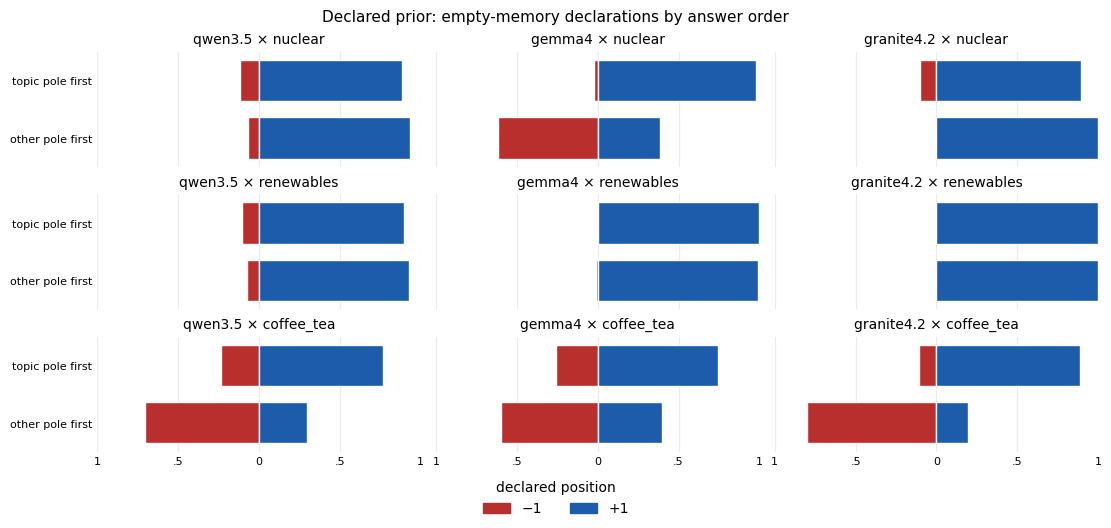

In [71]:
def empty_declarations(c):
    return pd.DataFrame([{"agent": u["exchange"]["sides"][role]["agent"], "y": d["empty"]["x"],
                          "topic_first": d["empty"]["topic_first"]}
                         for u in meetings(c) for role, d in u["declarations"].items()],
                        columns=["agent", "y", "topic_first"])


fig, pairs = panels(figsize=(11, 5.2), sharex=True, sharey=True)
for c, ax in pairs:
    df = empty_declarations(c)
    shares = pd.crosstab(df.topic_first, df.y, normalize="index").reindex([True, False])
    centred_bars(ax, shares, ("topic pole first", "other pole first"))
position_legend(fig, "declared position")
fig.suptitle("Declared prior: empty-memory declarations by answer order", fontsize=11);

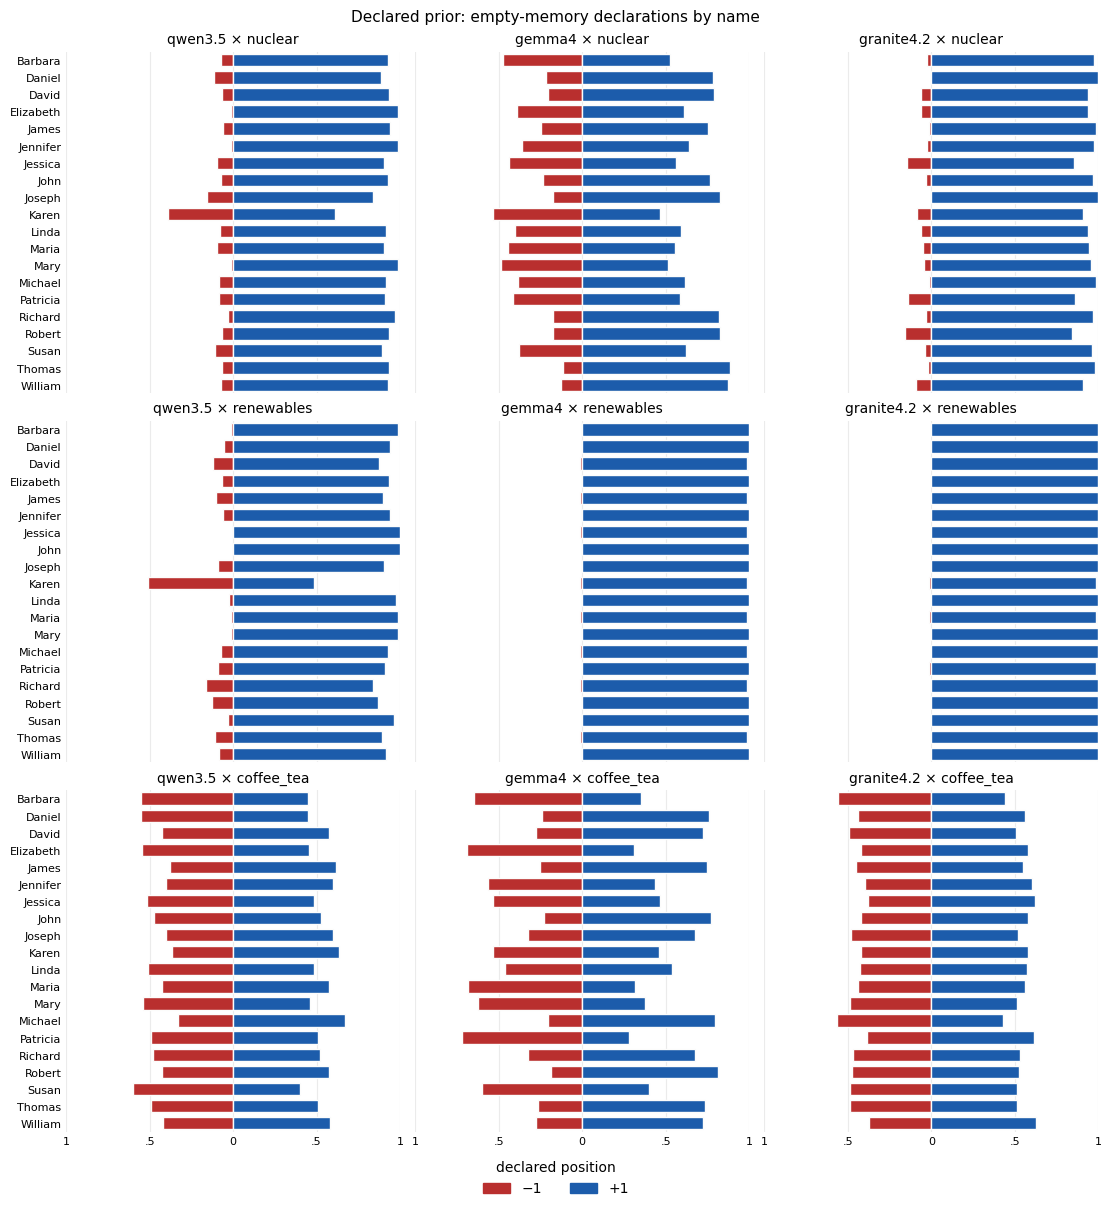

In [72]:
# By name, in one order across cells.
fig, pairs = panels(figsize=(11, 12), sharex=True, sharey=True)
for c, ax in pairs:
    df = empty_declarations(c)
    shares = pd.crosstab(df.agent, df.y, normalize="index")
    centred_bars(ax, shares, shares.index)
position_legend(fig, "declared position")
fig.suptitle("Declared prior: empty-memory declarations by name", fontsize=11);

## 3. Poles taken

The share of each pole in the one-entry declarations (both conditions), probes and self-reads,
and the self-read by argued position.

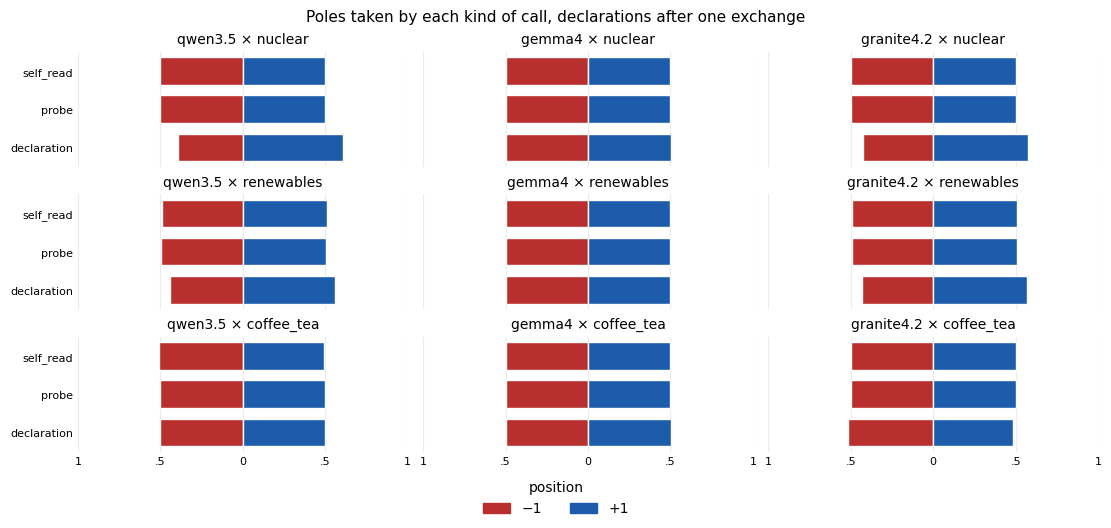

In [73]:
def taken(c):
    """The meetings' calls with only the one-entry declarations."""
    df = calls(c)
    return df[(df.kind != "declaration") | df.one_entry]


TAKEN_ORDER = ["self_read", "probe", "declaration"]   # top to bottom


fig, pairs = panels(figsize=(11, 5.2), sharex=True, sharey=True)
for c, ax in pairs:
    df = taken(c)
    centred_bars(ax, pd.crosstab(df.kind, df.x, normalize="index").reindex(TAKEN_ORDER), TAKEN_ORDER)
position_legend(fig, "position")
fig.suptitle("Poles taken by each kind of call, declarations after one exchange", fontsize=11);

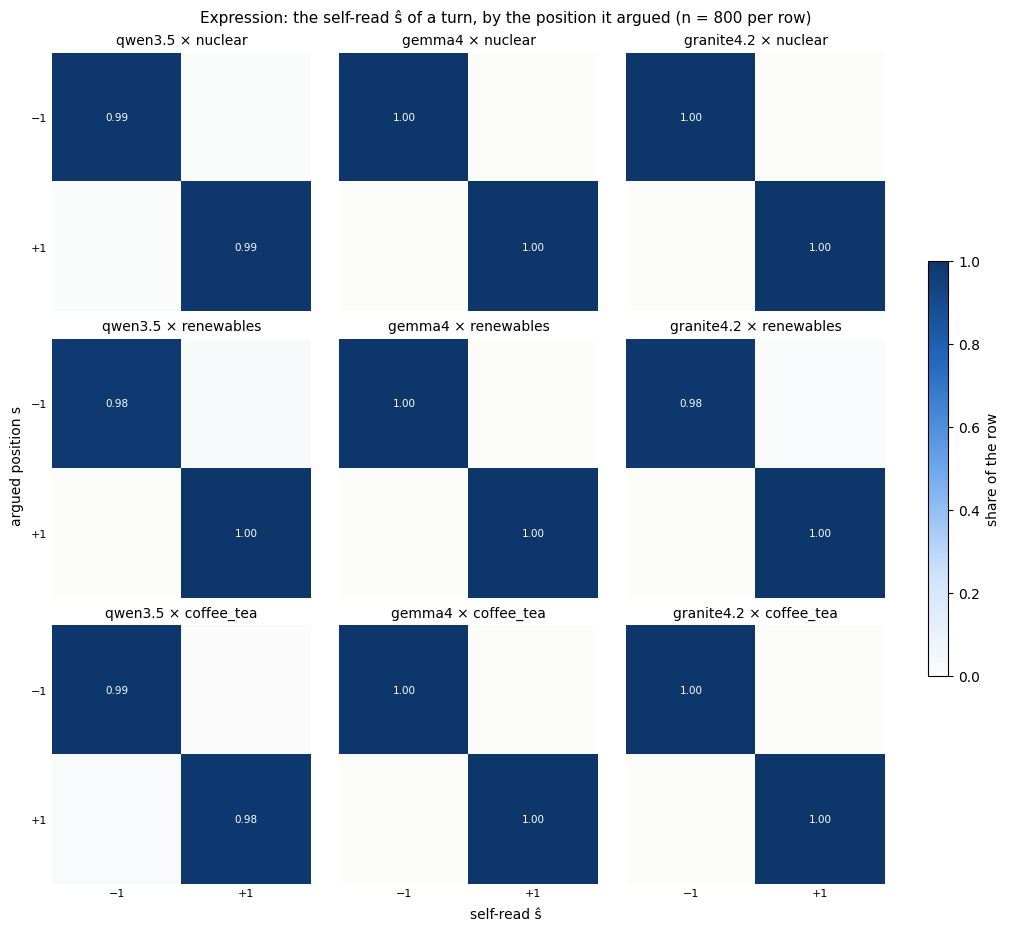

In [74]:
def self_read_table(c):
    d = metrics.turns(meetings(c))
    return pd.crosstab(d.s, d.self_read)


conditional_heatmaps(self_read_table, "Expression: the self-read ŝ of a turn, by the position it argued",
                     "self-read ŝ", "argued position s")

## 4. Parse retries and aborts; answer-order bias

A dropped unit is a parse abort (`build_audit.py`). The bias is half the difference in
mean x between the two answer orders, per kind of call (`metrics.order_bias`).

parse retries, aborts and drops: none


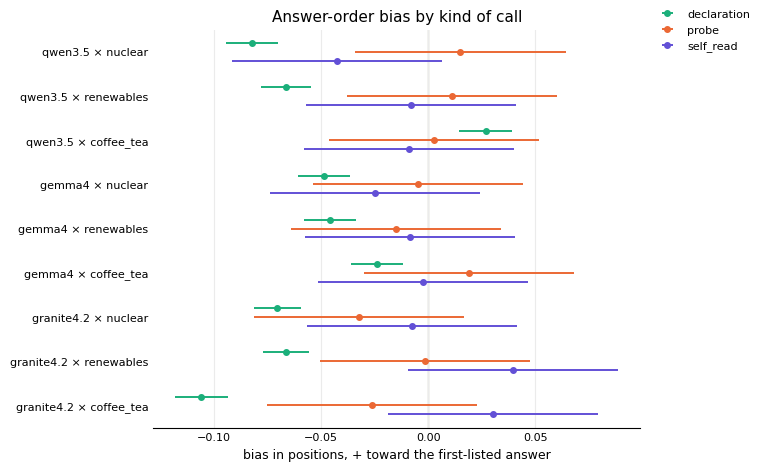

In [75]:
parse = {cell_label(c): Counter(ev["type"] for ev in events(d, ("parse_retry", "parse_abort", "dropped")))
         for c, d in cells.items()}
print("parse retries, aborts and drops:", {c: dict(n) for c, n in parse.items() if n} or "none")

bias = pd.DataFrame([{"cell": cell_label(c), "group": kind, **metrics.order_bias(g.to_dict("records"))}
                     for c in cells for kind, g in calls(c).groupby("kind")]).rename(columns={"bias": "est"})
fig, ax = plt.subplots(figsize=(7.5, 4.6), layout="constrained")
forest(ax, bias, KIND_COLOR, "bias in positions, + toward the first-listed answer", ref=0)
fig.legend(loc="outside right upper", frameon=False, fontsize=8)
ax.set_title("Answer-order bias by kind of call", fontsize=11);

## 5. Reliability

Test-retest from the reads' logprobs, with no re-asks. `metrics.reliability` gives, per read,
the variance between texts against a re-ask's, drawn first as `reliability` beside `agree`,
the chance a re-ask repeats the answer. The audit argues both poles evenly, which puts the
variance between texts near 1: pooled, `reliability` says the reads separate the poles, and a
settled run, whose inputs vary less, can read lower. Within one argued position both variances
are near 0 and their ratio is unstable, so by argued position `agree` is drawn. `metrics.read_gap` splits the self-read's mismatch with the
probe into sampling noise and the real gap between the two reads, by whether they drew one answer
order; the gap's difference between the two panels is order's part, and each bar should end at its
`mismatch` tick.

Ollama returns only the top 20 tokens and the drawn answer. An unlisted label counts as 0, so
`sampling` is a lower bound; `unread` is the share of calls under `metrics.LABEL_MASS_MIN`, which
give no distribution. The lines printed first show the masses on both sides of that bound and each
read's unread share. How closely the probe tracks the partner's self-read is in § 7.

qwen3.5 × nuclear label mass: largest unread 6.2e-04, smallest read 0.411; unread: self-read 0.009, probe 0.009
qwen3.5 × renewables label mass: largest unread 3.0e-04, smallest read 0.806; unread: self-read 0.009, probe 0.009
qwen3.5 × coffee_tea label mass: largest unread 9.8e-04, smallest read 0.390; unread: self-read 0.009, probe 0.016
gemma4 × nuclear label mass: largest unread nan, smallest read 0.998; unread: self-read 0.000, probe 0.000
gemma4 × renewables label mass: largest unread nan, smallest read 0.994; unread: self-read 0.000, probe 0.000
gemma4 × coffee_tea label mass: largest unread nan, smallest read 0.999; unread: self-read 0.000, probe 0.000
granite4.2 × nuclear label mass: largest unread nan, smallest read 0.656; unread: self-read 0.000, probe 0.000
granite4.2 × renewables label mass: largest unread nan, smallest read 0.204; unread: self-read 0.000, probe 0.000
granite4.2 × coffee_tea label mass: largest unread nan, smallest read 0.393; unread: self-read 0.000, prob

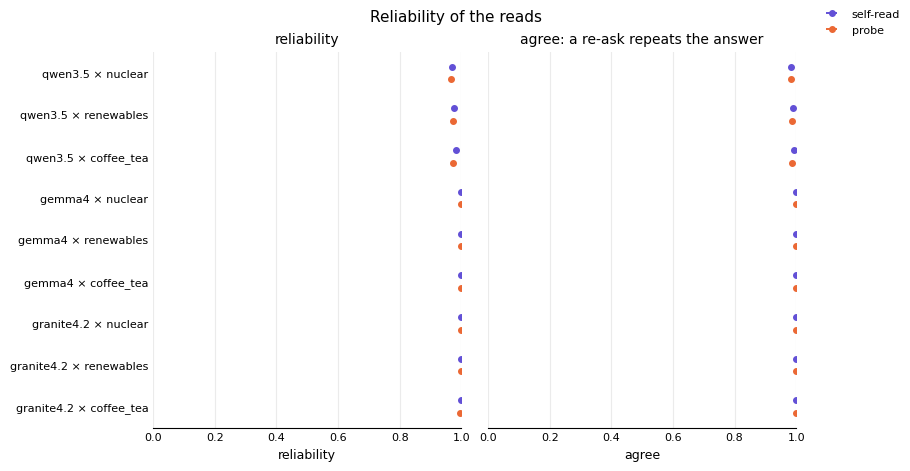

In [76]:
noise = {c: metrics.read_noise(meetings(c)) for c in cells}
rel = pd.concat({cell_label(c): metrics.reliability(n) for c, n in noise.items()}, names=["cell"]).reset_index(level=0)
rel["group"] = rel.read.map({"self": "self-read", "probe": "probe"})
for c, n in noise.items():
    mass = n[["self_mass", "probe_mass"]].stack()
    unread = rel[rel.cell == cell_label(c)].groupby("group").unread.first()
    print(cell_label(c), f"label mass: largest unread {mass[mass < metrics.LABEL_MASS_MIN].max():.1e}, "
                         f"smallest read {mass[mass >= metrics.LABEL_MASS_MIN].min():.3f}; "
                         f"unread: self-read {unread['self-read']:.3f}, probe {unread['probe']:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharey=True, layout="constrained")
for ax, (col, title) in zip(axes, (("reliability", "reliability"),
                                   ("agree", "agree: a re-ask repeats the answer"))):
    forest(ax, rel.assign(est=rel[col], lo=rel[col], hi=rel[col]), READ_COLOR, col)
    ax.set_xlim(0, 1)
    ax.set_title(title, fontsize=10)
fig.legend(handles=axes[0].get_legend_handles_labels()[0], loc="outside right upper", frameon=False, fontsize=8)
fig.suptitle("Reliability of the reads", fontsize=11);

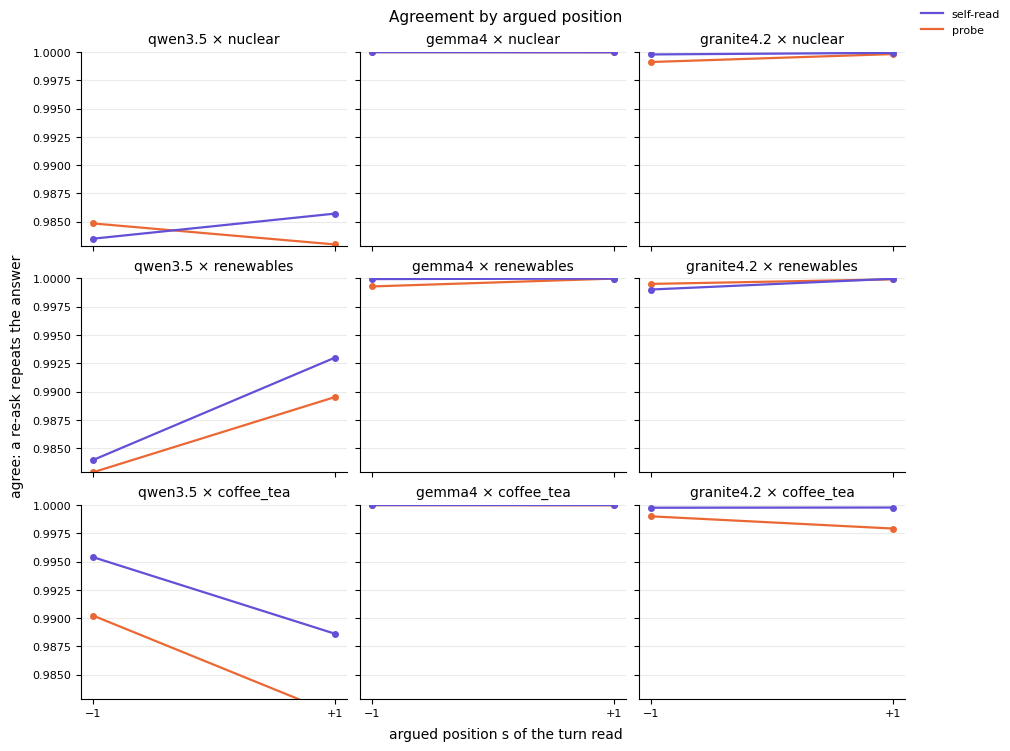

In [77]:
# By the argued position of the turn read: agree, since within one pole the ratio is near 0 / 0.
fig, pairs = panels(figsize=(10, 7.4), sharex=True, sharey=True)
for c, ax in pairs:
    r = metrics.reliability(noise[c], by="s")
    for read, g in r.groupby("read"):
        ax.plot(g.s, g.agree, color=READ_COLOR["self-read" if read == "self" else "probe"],
                marker="o", ms=4, lw=1.6)
    ax.set(ylim=(None, 1), xticks=list(POSITION_LABEL))
    ax.set_xticklabels(POSITION_LABEL.values())
    ax.grid(axis="y", color="0.92")
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.legend(handles=[Line2D([], [], color=c, lw=1.6, label=r) for r, c in READ_COLOR.items()],
           loc="outside right upper", frameon=False, fontsize=8)
fig.supxlabel("argued position s of the turn read", fontsize=10)
fig.supylabel("agree: a re-ask repeats the answer", fontsize=10)
fig.suptitle("Agreement by argued position", fontsize=11);

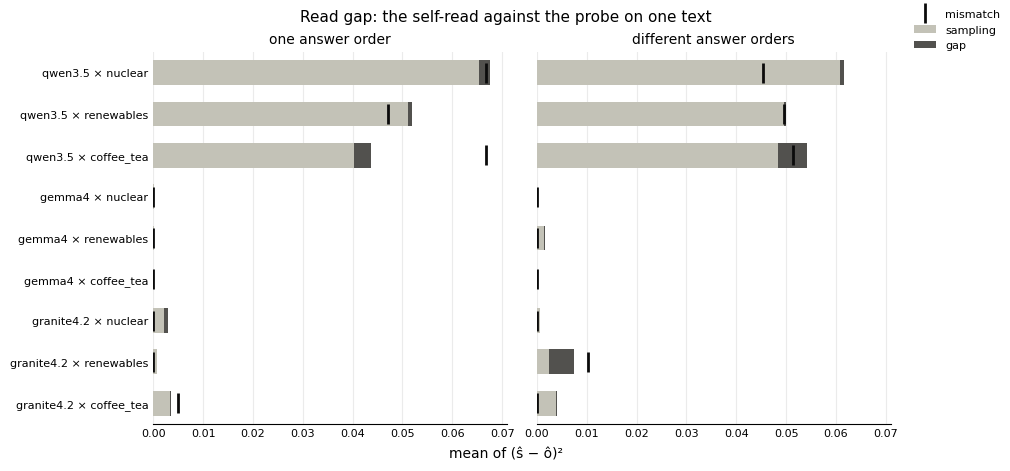

In [78]:
# Each bar is sampling + gap; the tick is the observed mismatch they should add up to.
gap = pd.concat({cell_label(c): metrics.read_gap(n) for c, n in noise.items()}, names=["cell"]).reset_index()
labels = list(dict.fromkeys(gap.cell))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True, layout="constrained")
for ax, (same, title) in zip(axes, ((True, "one answer order"), (False, "different answer orders"))):
    g = gap[gap.same_order == same].set_index("cell").reindex(labels)
    y = np.arange(len(labels))
    ax.barh(y, g.sampling, height=0.6, color="#c3c2b7", label="sampling")
    ax.barh(y, g.gap, left=g.sampling, height=0.6, color="#52514e", label="gap")
    ax.plot(g.mismatch, y, ls="none", marker="|", ms=14, mew=2, color="#0b0b0b", label="mismatch")
    ax.set_yticks(y, labels)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.set_title(title, fontsize=10)
    ax.grid(axis="x", color="0.92")
    ax.set_axisbelow(True)
    ax.tick_params(length=0, labelsize=8)
    ax.spines[["top", "right", "left"]].set_visible(False)
fig.legend(handles=axes[0].get_legend_handles_labels()[0], loc="outside right upper", frameon=False, fontsize=8)
fig.supxlabel("mean of (ŝ − ô)²", fontsize=10)
fig.suptitle("Read gap: the self-read against the probe on one text", fontsize=11);

## 6. Misperception, expression inconsistency

- **Misperception:** the share of probes ô unlike the partner's self-read, by both argued positions.
  The probe never sees the perceiver's position, so a change down a column would mean leakage.
- **Expression inconsistency:** by argued position, 1 − the diagonal of § 3's expression heatmap;
  below, the channel's lean toward a pole (`metrics.expression_bias`).

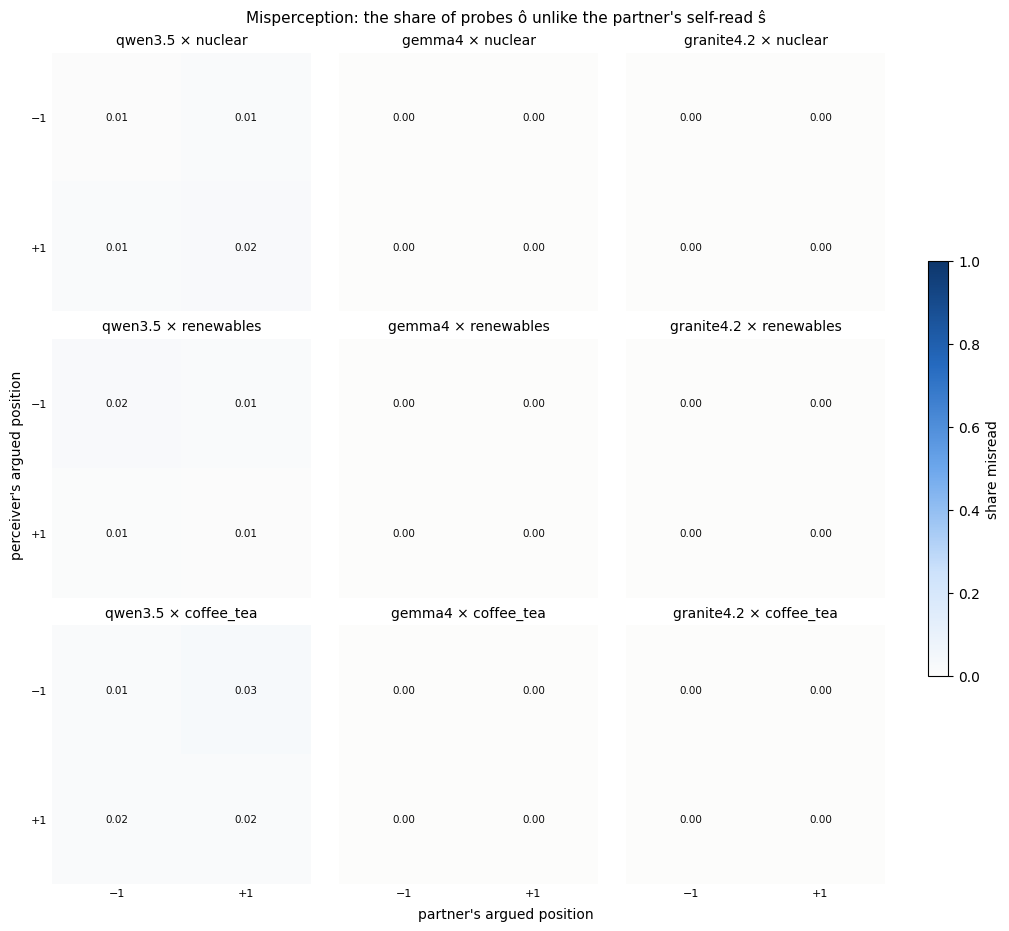

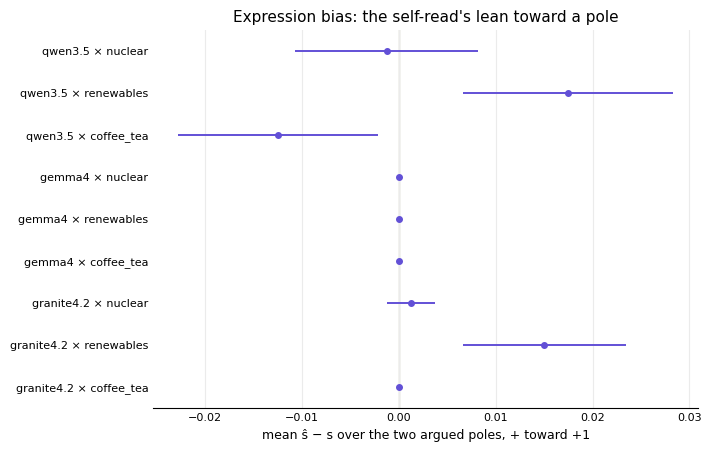

In [79]:
def misread_table(c):
    p = metrics.perception(meetings(c)).dropna(subset=["partner_self_read"])
    return (p.assign(misread=(p.o_hat != p.partner_self_read).astype(float))
            .pivot_table("misread", "s", "partner_s", aggfunc="mean")
            .reindex(index=list(POSITION_LABEL), columns=list(POSITION_LABEL)))


norm = Normalize(0, 1)
fig, pairs = panels(figsize=(10, 9.2), sharex=True, sharey=True)
for c, ax in pairs:
    t = misread_table(c)
    im = position_heatmap(ax, t, SHARE, norm)
    annotate(ax, t, SHARE, norm, lambda v: not np.isnan(v), lambda v: f"{v:.2f}")
fig.supxlabel("partner's argued position", fontsize=10)
fig.supylabel("perceiver's argued position", fontsize=10)
fig.suptitle("Misperception: the share of probes ô unlike the partner's self-read ŝ", fontsize=11)
fig.colorbar(im, ax=[ax for _, ax in pairs], shrink=0.5, label="share misread")

lean = pd.DataFrame([{"cell": cell_label(c), "group": "self-read", **metrics.expression_bias(metrics.turns(meetings(c)))}
                     for c in cells]).rename(columns={"bias": "est"})
fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
forest(ax, lean, {"self-read": READ_COLOR["self-read"]}, "mean ŝ − s over the two argued poles, + toward +1", ref=0)
ax.set_title("Expression bias: the self-read's lean toward a pole", fontsize=11);

## 7. Perception

The mean probe ô by both argued positions, the two roles pooled: what a run logs as ô. The
perceiver's own position should not move it, so each column should hold down its rows. Below, the
distribution of ô by the partner's argued position, pooled over the perceiver's; then ô against the
partner's self-read, and against the perceiver's own within each pole the partner argued. The surrogate draws from exactly these
exchanges, each meeting in both orientations (`surrogate.Pool.from_audit`).

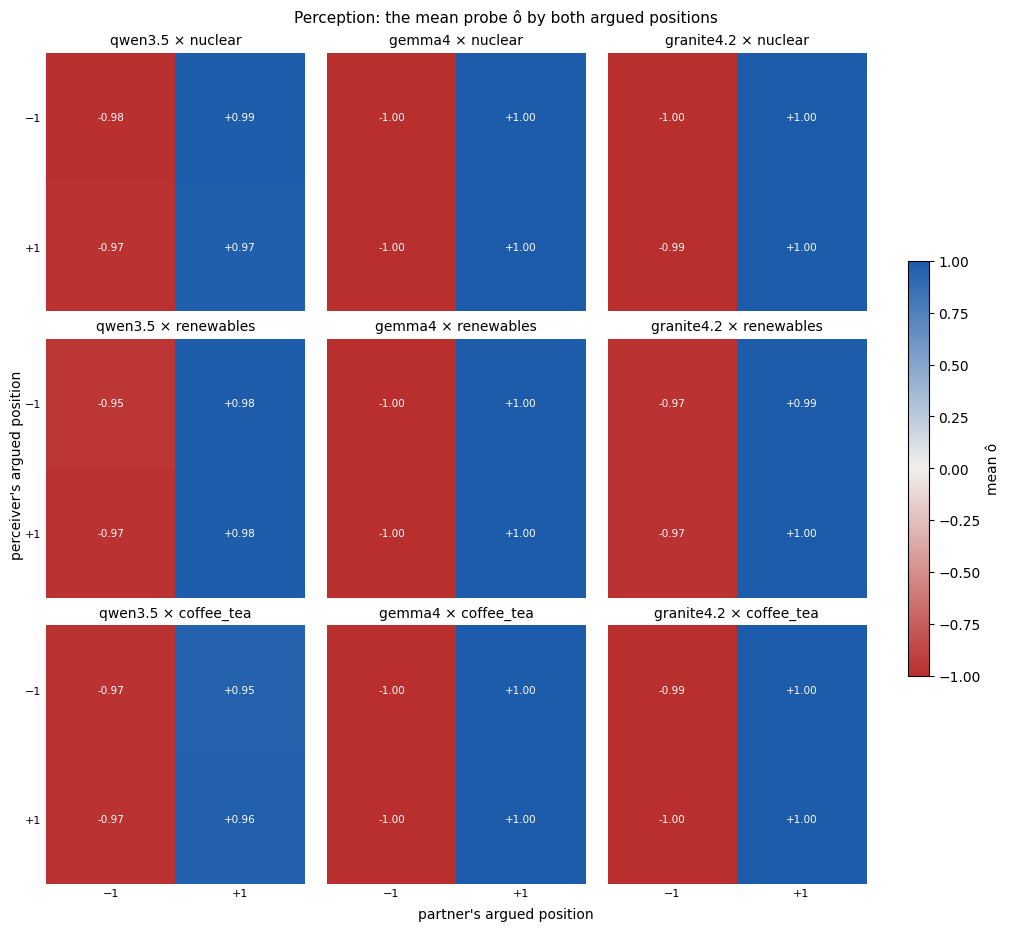

In [80]:
def mean_probe_table(c):
    p = metrics.perception(meetings(c))
    return (p.pivot_table("o_hat", "s", "partner_s", aggfunc="mean")
            .reindex(index=list(POSITION_LABEL), columns=list(POSITION_LABEL)))


norm = TwoSlopeNorm(0, -1, 1)
fig, pairs = panels(figsize=(10, 9.2), sharex=True, sharey=True)
for c, ax in pairs:
    t = mean_probe_table(c)
    im = position_heatmap(ax, t, SHIFT, norm)
    annotate(ax, t, SHIFT, norm, lambda v: not np.isnan(v), lambda v: f"{v:+.2f}")
fig.supxlabel("partner's argued position", fontsize=10)
fig.supylabel("perceiver's argued position", fontsize=10)
fig.suptitle("Perception: the mean probe ô by both argued positions", fontsize=11)
fig.colorbar(im, ax=[ax for _, ax in pairs], shrink=0.5, label="mean ô");

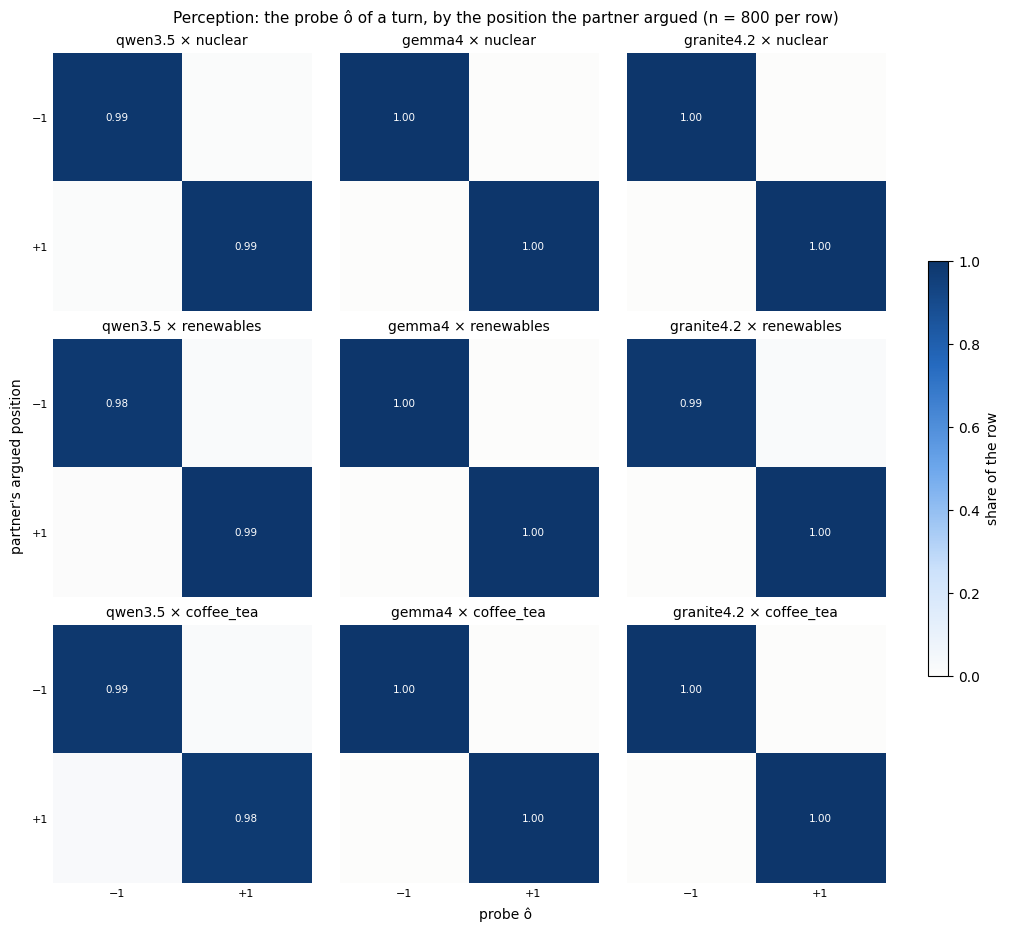

In [81]:
# Pooled over the perceiver's own argued position.
def probe_table(c):
    p = metrics.perception(meetings(c))
    return pd.crosstab(p.partner_s, p.o_hat)


conditional_heatmaps(probe_table, "Perception: the probe ô of a turn, by the position the partner argued",
                     "probe ô", "partner's argued position")

,"r(ô, partner's ŝ)",ô = partner's ŝ,n tracking,"r(ô, own ŝ)",n own
qwen3.5 × nuclear,0.970,0.985,1600.0,-2.498e-03,1600.0
qwen3.5 × renewables,0.974,0.987,1600.0,-1.145e-02,1600.0
qwen3.5 × coffee_tea,0.961,0.981,1600.0,8.642e-03,1600.0
gemma4 × nuclear,1.000,1.000,1600.0,0.000e+00,1600.0
gemma4 × renewables,1.000,1.000,1600.0,0.000e+00,1600.0
gemma4 × coffee_tea,1.000,1.000,1600.0,0.000e+00,1600.0
granite4.2 × nuclear,1.000,1.000,1600.0,2.498e-03,1600.0
granite4.2 × renewables,0.998,0.999,1600.0,-1.875e-04,1600.0
granite4.2 × coffee_tea,0.999,0.999,1600.0,-1.250e-03,1600.0


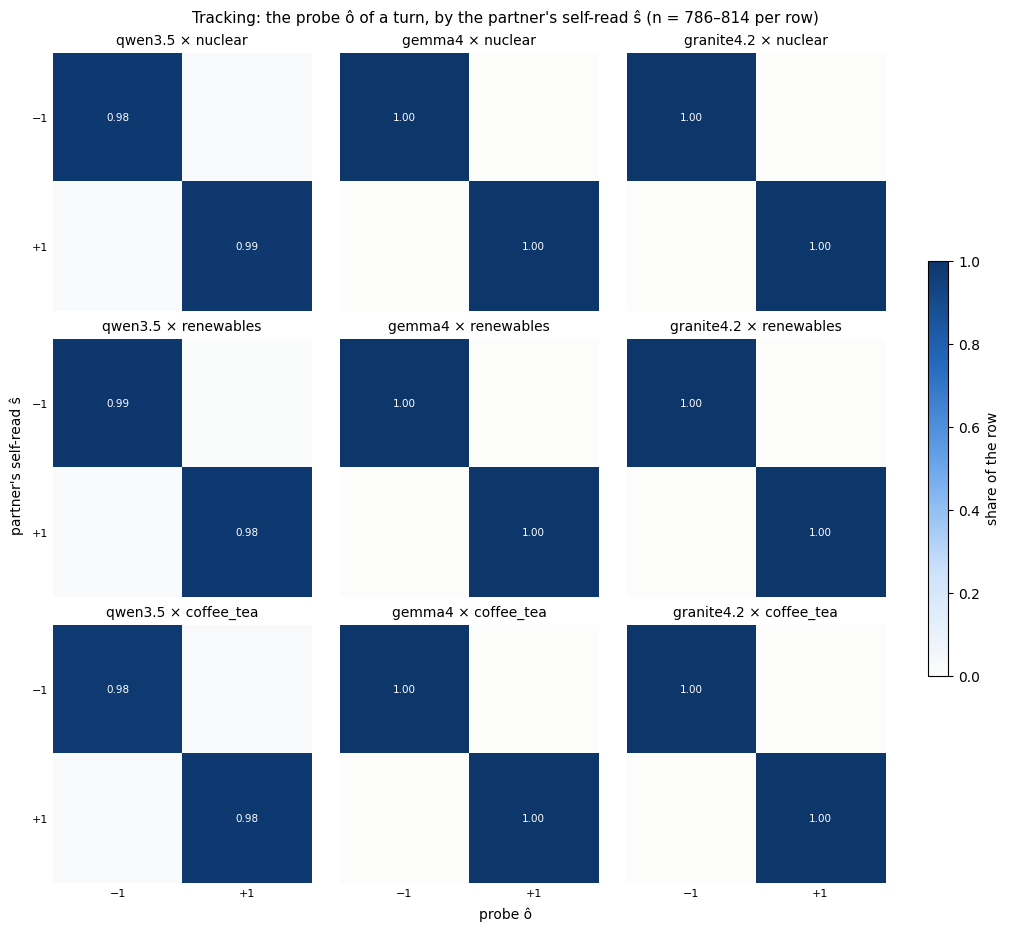

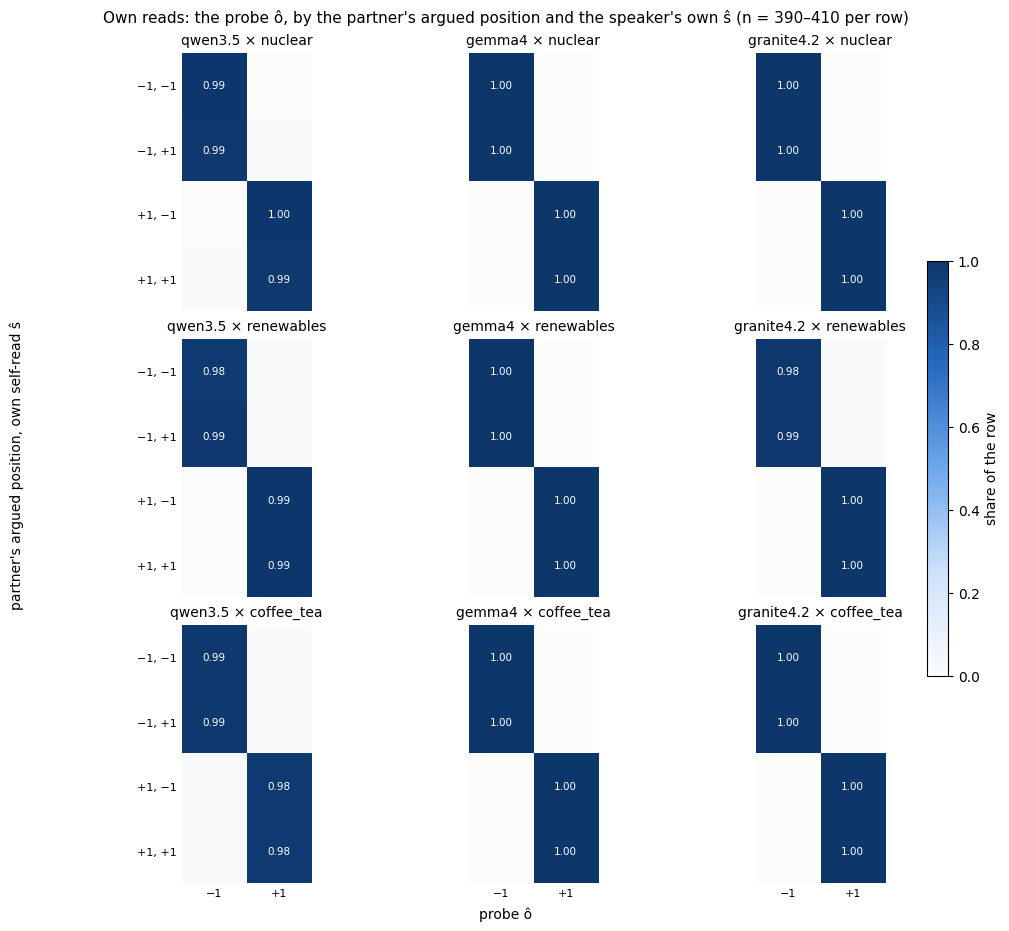

In [82]:
# Do the two reads move together? Partner's self-read ŝ against the probe ô says how well ô tracks
# the text it reads; the speaker's own ŝ against its own ô is what r̂ = ŝ·ô multiplies. Pooled
# over the partner's argued position, the strata's balance puts every own-ŝ row near 0.5, so the
# own pair is split by it: within a partner's pole, rows that differ are the own read
# colouring the probe (projection).
def tracking_table(c):
    p = metrics.perception(meetings(c)).dropna(subset=["partner_self_read"])
    return pd.crosstab(p.partner_self_read, p.o_hat)


def own_pair_table(c):
    p = metrics.perception(meetings(c)).dropna(subset=["self_read"]).astype({"self_read": int})
    return pd.crosstab([p.partner_s, p.self_read], p.o_hat)


OWN_PAIR_ROWS = {(ps, s): f"{POSITION_LABEL[ps]}, {POSITION_LABEL[s]}"
                 for ps in POSITION_LABEL for s in POSITION_LABEL}


conditional_heatmaps(tracking_table, "Tracking: the probe ô of a turn, by the partner's self-read ŝ",
                     "probe ô", "partner's self-read ŝ")
conditional_heatmaps(own_pair_table, "Own reads: the probe ô, by the partner's argued position and the speaker's own ŝ",
                     "probe ô", "partner's argued position, own self-read ŝ", OWN_PAIR_ROWS)


def read_correlations(c):
    p = metrics.perception(meetings(c)).dropna(subset=["partner_self_read"]).astype({"o_hat": float, "partner_self_read": float})
    d = metrics.turns(meetings(c)).dropna(subset=["self_read"]).astype({"o_hat": float, "self_read": float})
    return {"r(ô, partner's ŝ)": p.o_hat.corr(p.partner_self_read),
            "ô = partner's ŝ": (p.o_hat == p.partner_self_read).mean(), "n tracking": len(p),
            "r(ô, own ŝ)": d.o_hat.corr(d.self_read), "n own": len(d)}


display(pd.DataFrame({cell_label(c): read_correlations(c) for c in cells}).T)

## 8. One-step response and signatures

On the one-entry declarations, per condition: `full` shows the exchange's two turns, `own` the
agent's own turn alone, the negative control, whose rows should stay flat along ô. The signature table is read descriptively ([README](../README.md#signatures)
§ Signatures): with one entry, habit's K = α_K ŝ and feedback's ΔQ = αô, so habit moves y with ŝ
and feedback with ô. One entry identifies only the products γ_Kα_K and βα. Each model's BIC is
drawn against the cell's best, descriptively, with the best model's parameters beside it.

In [83]:
fits = {}
for c in cells:
    for cond in CONDITIONS:
        decls = one_entry(c, cond)
        if not decls:
            continue
        print(c, cond, len(decls), "declarations")
        display(metrics.signatures(decls))
        data = fit.arrays(decls)
        fits[c, cond] = {m: fit.fit(data, m) for m in fit.MODELS}

nuclear_qwen3.5-nodraft-4b full 1600 declarations


,s,o,n,mean,lo,hi
0,-1,-1,399,-0.333,-0.426,-0.241
1,-1,1,402,-0.667,-0.740,-0.594
2,1,-1,400,0.945,0.913,0.977
3,1,1,399,0.855,0.804,0.906


nuclear_qwen3.5-nodraft-4b own 1600 declarations


,s,o,n,mean,lo,hi
0,-1,-1,399,-0.504,-0.589,-0.419
1,-1,1,402,-0.398,-0.488,-0.308
2,1,-1,400,0.895,0.851,0.939
3,1,1,399,0.890,0.845,0.935


renewables_qwen3.5-nodraft-4b full 1600 declarations


,s,o,n,mean,lo,hi
0,-1,-1,384,-0.536,-0.621,-0.452
1,-1,1,402,-0.642,-0.717,-0.567
2,1,-1,407,0.956,0.927,0.984
3,1,1,407,0.902,0.860,0.944


... (26 outputs left out)

coffee_tea_granite4.2-nodraft-3b full 1600 declarations


,s,o,n,mean,lo,hi
0,-1,-1,399,-0.975,-0.997,-0.953
1,-1,1,401,-0.820,-0.876,-0.764
2,1,-1,400,0.560,0.479,0.641
3,1,1,400,0.995,0.985,1.005


coffee_tea_granite4.2-nodraft-3b own 1600 declarations


,s,o,n,mean,lo,hi
0,-1,-1,399,-0.99,-1.004,-0.976
1,-1,1,401,-1.00,-1.000,-1.000
2,1,-1,400,0.99,0.976,1.004
3,1,1,400,0.99,0.976,1.004


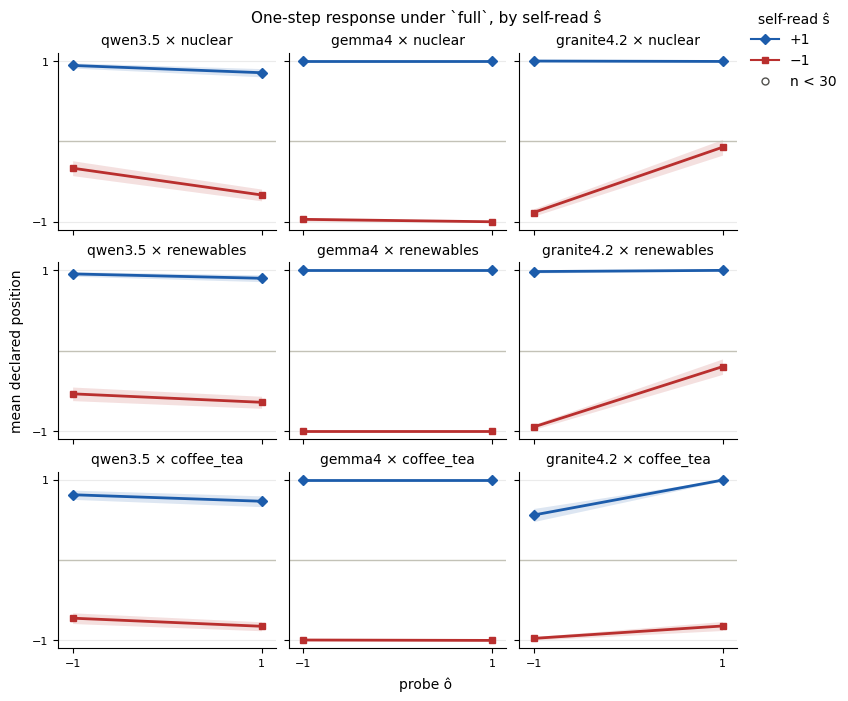

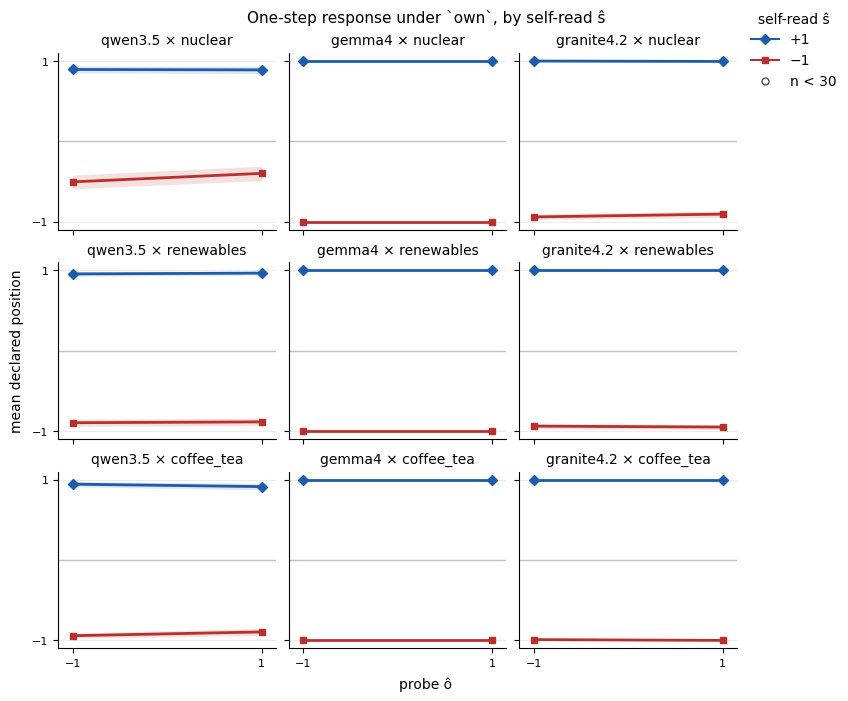

In [84]:
# The signature table drawn: mean y against ô per ŝ. Habit separates the lines by ŝ and
# leaves each flat in ô; feedback tilts both alike toward ô. Below metrics.THIN_N a point
# is hollow and outside the band.
MARKER = {-1: "s", 1: "D"}


def response_figure(decls_of, title):
    fig, pairs = panels(figsize=(8.4, 6.9), sharex=True, sharey=True)
    for c, ax in pairs:
        for s, t in metrics.signatures(decls_of(c)).groupby("s"):
            color, solid = POSITION_COLOR[s], t["n"] >= metrics.THIN_N
            ax.fill_between(t["o"], t["lo"].where(solid), t["hi"].where(solid), color=color, alpha=0.15, lw=0)
            ax.plot(t["o"], t["mean"], color=color, lw=2)
            for points, fill in ((solid, color), (~solid, "white")):
                ax.plot(t["o"][points], t["mean"][points], ls="none", marker=MARKER[s], ms=5, mec=color, mfc=fill)
        ax.axhline(0, color="#c3c2b7", lw=1)
        ax.set(xlim=(-1.15, 1.15), ylim=(-1.1, 1.1), xticks=list(POSITION_LABEL), yticks=list(POSITION_LABEL))
        ax.grid(axis="y", color="0.92")
        ax.tick_params(labelsize=8)
        ax.spines[["top", "right"]].set_visible(False)
    fig.supxlabel("probe ô", fontsize=10)
    fig.supylabel("mean declared position", fontsize=10)
    fig.suptitle(f"One-step response {title}, by self-read ŝ", fontsize=11)
    fig.legend(handles=[Line2D([], [], color=POSITION_COLOR[s], marker=MARKER[s], ms=5, label=POSITION_LABEL[s])
                        for s in reversed(POSITION_LABEL)]
                       + [Line2D([], [], color="#52514e", mfc="white", marker="o", ls="none", ms=5,
                                 label=f"n < {metrics.THIN_N}")],
               title="self-read ŝ", loc="outside right upper", frameon=False)


for cond in CONDITIONS:
    response_figure(lambda c: one_entry(c, cond), f"under `{cond}`")

model      b  kappa  gamma_K    a_K   beta      a
qwen3.5 × nuclear       full    M1  0.927 -0.114    2.050  0.990    NaN    NaN
                        own     M1  0.950 -0.108    1.921  1.000    NaN    NaN
qwen3.5 × renewables    full    M1  0.972  0.085    2.485  0.938    NaN    NaN
                        own     M1  0.522  0.271    3.886  0.877    NaN    NaN
qwen3.5 × coffee_tea    full    M1 -0.006  0.625    2.258  0.970    NaN    NaN
                        own     M1  0.064  0.368    3.687  0.893    NaN    NaN
gemma4 × nuclear        full    M1  8.747 -8.675   30.422  0.710    NaN    NaN
                        own     M1  0.204 -0.157   19.148  1.000    NaN    NaN
gemma4 × renewables     full    M1  0.381 -0.216   19.665  1.000    NaN    NaN
                        own     M1  0.164 -0.161   19.155  1.000    NaN    NaN
gemma4 × coffee_tea     full    M1  9.420 -9.691   33.681  0.745    NaN    NaN
                        own     M1  0.329 -0.031   19.093  1.000    NaN    NaN
granite4.2 × nuclear    full    M2  3.271 -1.229    5.090  0.981  2.019  0.812
                        own     M1  1.754 -1.800    6.480  0.928    NaN    NaN
granite4.2 × renewables full    M2  2.769 -1.836    5.438  1.000  2.516  0.865
                        own     M1  9.073 -1.520   17.855  0.756    NaN    NaN
granite4.2 × coffee_tea full    M2 -0.562 -7.991   12.639  0.841  4.258  0.402
                        own     M1 -0.352 -0.812    8.368  0.709    NaN    NaN

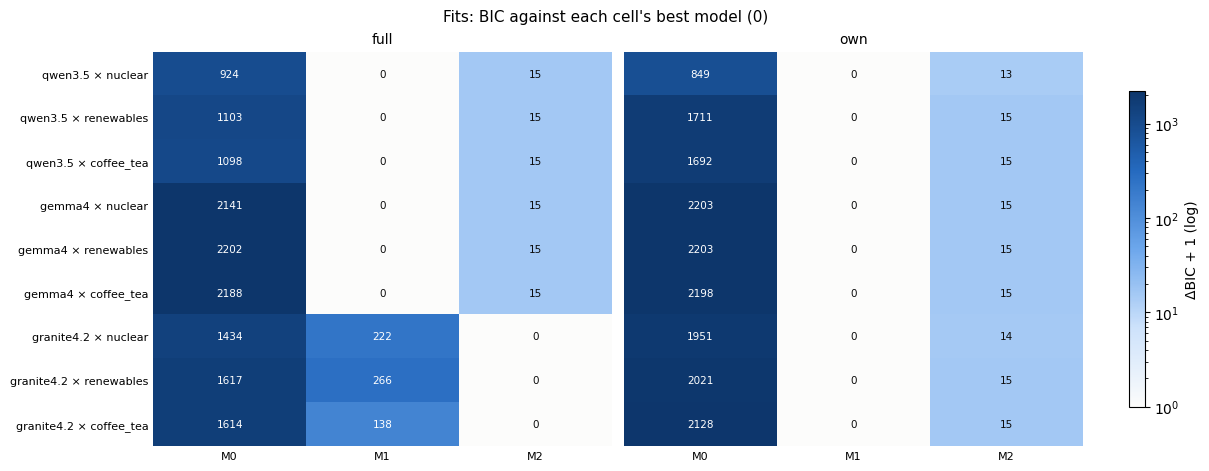

In [85]:
# BIC against the cell's best fit, per condition; the best model's parameters below.
delta = {}
for cond in CONDITIONS:
    bic = pd.DataFrame({cell_label(c): {m: f["bic"] for m, f in fs.items()}
                        for (c, k), fs in fits.items() if k == cond}).T
    if not bic.empty:
        delta[cond] = bic.sub(bic.min(axis=1), axis=0)
if delta:
    norm = LogNorm(1, max(10, max(d.max().max() for d in delta.values()) + 1))
    fig, axes = plt.subplots(1, len(delta), figsize=(12, 4.6), sharey=True, layout="constrained", squeeze=False)
    for ax, (cond, d) in zip(axes[0], delta.items()):
        im = ax.imshow(d.to_numpy() + 1, cmap=SHARE, norm=norm, aspect="auto")
        annotate(ax, d, SHARE, lambda v: norm(v + 1), lambda v: True, lambda v: f"{v:.0f}")
        ax.set_xticks(range(d.shape[1]), d.columns, fontsize=8)
        ax.set_yticks(range(len(d)), d.index, fontsize=8)
        ax.tick_params(length=0)
        ax.spines[:].set_visible(False)
        ax.set_title(cond, fontsize=10)
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label="ΔBIC + 1 (log)")
    fig.suptitle("Fits: BIC against each cell's best model (0)", fontsize=11)
    best = {}
    for (c, cond), fs in fits.items():
        m = min(fs, key=lambda k: fs[k]["bic"])
        best[cell_label(c), cond] = {"model": m, **fs[m]["params"]}
    display(pd.DataFrame.from_dict(best, orient="index"))

## 9. Order, serial position, settled windows

Each window is declared under both conditions on the same entries.
- **Order:** mean y by window; ΔQ ignores the order, habit's effect ignores the
  partners.
- **Serial position:** the effect of entry k (redrawn with its partner on the opposite pole)
  by its lag from the latest entry, against the geometric weight every trace assumes.
- **Settled:** where declarations land when every turn of the window argues one pole,
  with the probability of the other beside each.

In [86]:
def window_frame(us, kind):
    """One row per window declaration: key, condition, y."""
    rows = [{"key": u["key"], "condition": cond, "y": d["x"]}
            for u in us if u["kind"] == kind for cond, d in u["declaration"].items()]
    return pd.DataFrame(rows, columns=["key", "condition", "y"])


def serial_effects(c):
    """Serial windows with p, k and the effect of moving k's partner against the settled
    mean of the same condition."""
    settled = window_frame(units[c]["windows"], "settled")
    serial = window_frame(units[c]["windows"], "serial")
    if serial.empty:
        return serial
    serial[["p", "k"]] = serial.key.str.split(":", expand=True)[[1, 2]].astype(int)
    base = settled.assign(p=settled.key.str.split(":").str[1].astype(int)).groupby(["condition", "p"]).y.mean()
    at = pd.MultiIndex.from_frame(serial[["condition", "p"]])
    serial["effect"] = serial.p * (base.reindex(at).to_numpy() - serial.y)
    return serial

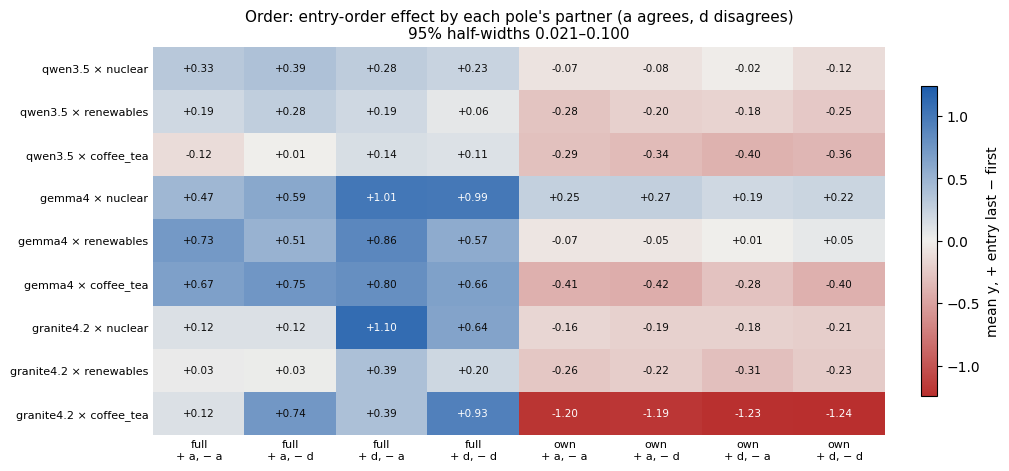

In [87]:
# Each window against its reversal: the mean y with the + entry last minus with
# it first, each side 770 calls. Positive: the later entry weighs more. ΔQ predicts 0.
ORDER_WINDOW = ["condition", "plus", "minus", "plus_last"]


def order_frame(c):
    f = window_frame(units[c]["windows"], "order")
    spec = f.key.str.split(":", expand=True)
    first = spec[2].astype(int)
    plus, minus = spec[1].str[0].where(first == 1, spec[1].str[1]), spec[1].str[1].where(first == 1, spec[1].str[0])
    return f.assign(plus=plus, minus=minus, plus_last=first == -1)


def order_effects(c):
    means = order_frame(c).groupby(ORDER_WINDOW).y.mean().unstack("plus_last")
    return means[True] - means[False]


def order_half_widths(c):
    """95% half-width of each effect."""
    y = order_frame(c).groupby(ORDER_WINDOW).y
    var = (y.var() / y.size()).unstack("plus_last")
    return metrics.Z95 * np.sqrt(var[True] + var[False])


effects = pd.DataFrame({cell_label(c): order_effects(c) for c in cells if units[c]["windows"]}).T
if effects.empty:
    print("no windows yet")
else:
    half = pd.DataFrame({cell_label(c): order_half_widths(c) for c in cells if units[c]["windows"]}).T
    lim = max(effects.abs().max().max(), 0.01)   # a stub's effects may all be 0
    norm = TwoSlopeNorm(0, -lim, lim)
    fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
    im = ax.imshow(effects.to_numpy(), cmap=SHIFT, norm=norm, aspect="auto")
    annotate(ax, effects, SHIFT, norm, lambda v: True, lambda v: f"{v:+.2f}")
    ax.set_xticks(range(effects.shape[1]), [f"{cond}\n+ {p}, − {q}" for cond, p, q in effects.columns], fontsize=8)
    ax.set_yticks(range(len(effects)), effects.index, fontsize=8)
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title("Order: entry-order effect by each pole's partner (a agrees, d disagrees)\n"
                 f"95% half-widths {half.min().min():.3f}–{half.max().max():.3f}", fontsize=11)
    fig.colorbar(im, ax=ax, shrink=0.8, label="mean y, + entry last − first");

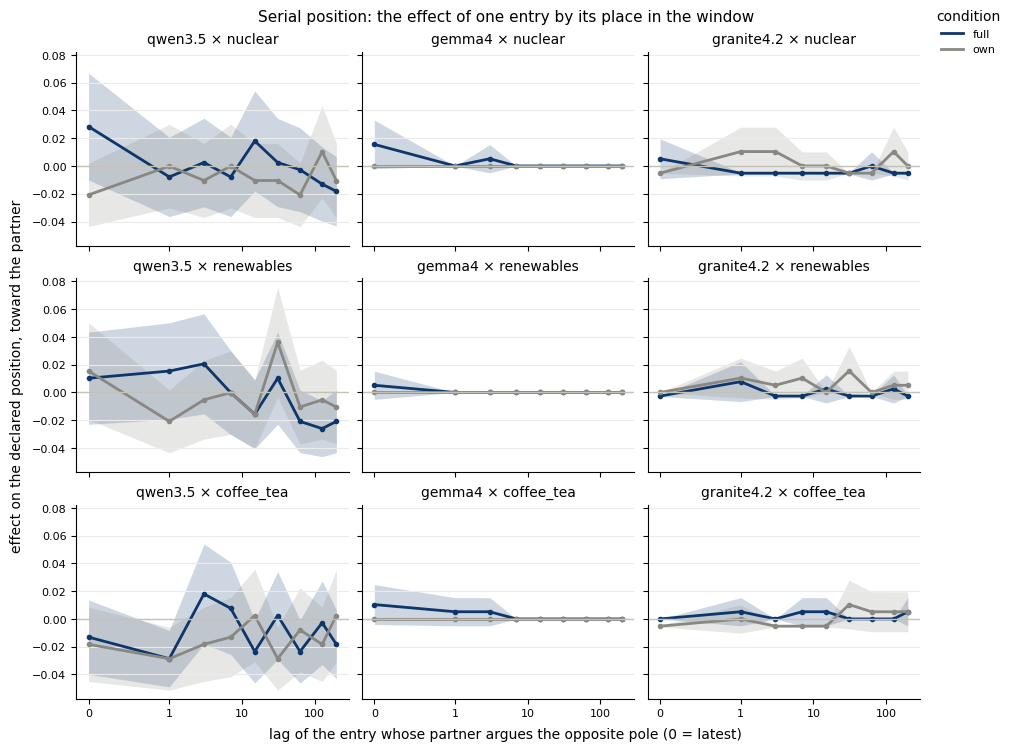

In [88]:
# Pooled over the two poles, the unit the schedule's 193 calls are sized for (2 · 193), per
# condition. Lag 0 is the latest entry; the band ignores the settled baseline's own error.
fig, pairs = panels(figsize=(10, 7.4), sharex=True, sharey=True)
for c, ax in pairs:
    serial = serial_effects(c)
    if serial.empty:
        ax.axis("off")
        continue
    serial["lag"] = serial.k.max() - serial.k
    for cond, g in serial.groupby("condition"):
        m = g.groupby("lag").effect.agg(["mean", "std", "size"])
        half = metrics.Z95 * m["std"] / np.sqrt(m["size"])
        ax.fill_between(m.index, m["mean"] - half, m["mean"] + half, color=COND_COLOR[cond], alpha=0.2, lw=0)
        ax.plot(m.index, m["mean"], color=COND_COLOR[cond], lw=2, marker="o", ms=3)
    ax.set_xscale("symlog", linthresh=1)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,g}"))   # decimal labels on log axes, not 10^n
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.grid(axis="y", color="0.92")
    ax.tick_params(labelsize=8)
    ax.spines[["top", "right"]].set_visible(False)
fig.supxlabel("lag of the entry whose partner argues the opposite pole (0 = latest)", fontsize=10)
fig.supylabel("effect on the declared position, toward the partner", fontsize=10)
fig.legend(handles=[Line2D([], [], color=COND_COLOR[k], lw=2, label=k) for k in CONDITIONS],
           title="condition", loc="outside right upper", frameon=False, fontsize=8)
fig.suptitle("Serial position: the effect of one entry by its place in the window", fontsize=11);

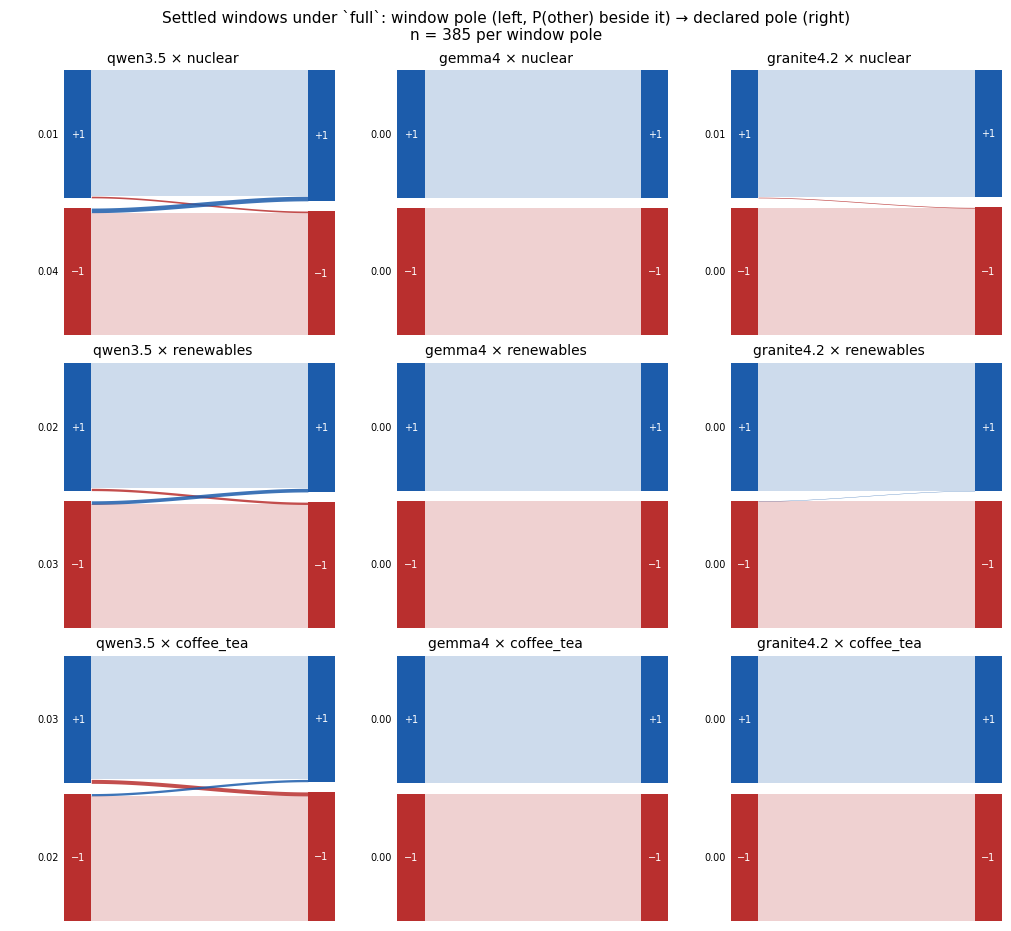

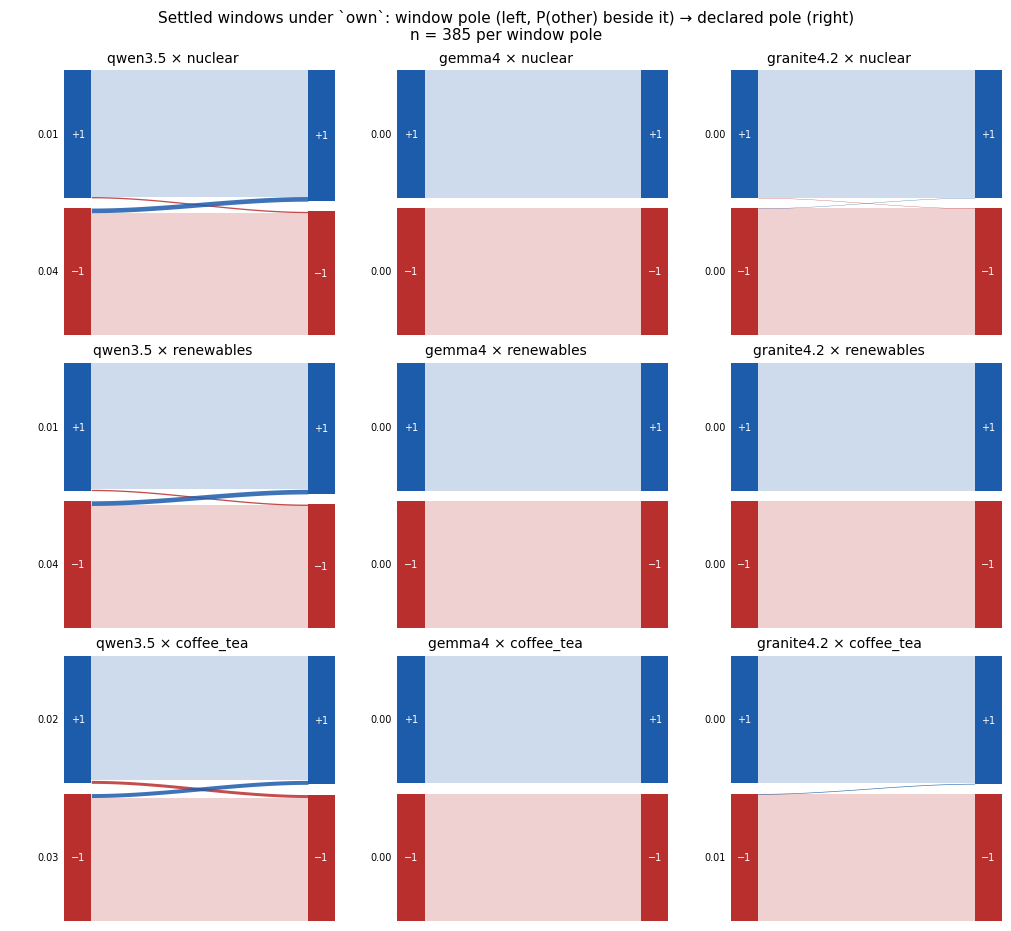

In [92]:
# Each panel's left column is the pole every entry argues, 385 calls each, with P(other)
# beside it; the right column is where the declarations land. A ribbon's width is its
# count: a stay is faint, a move is drawn in the colour it lands on. One figure per condition.
TOP_DOWN = sorted(POSITION_LABEL, reverse=True)   # + at the top
NODE, GAP = 0.1, 0.04   # node width; gap between nodes, as a share of a column


def alluvial(ax, counts):
    """``counts`` (window pole × declared pole) as ribbons from left to right."""
    counts = counts.reindex(index=TOP_DOWN, columns=TOP_DOWN, fill_value=0)
    total = counts.to_numpy().sum()
    gap, gaps = GAP * total, len(TOP_DOWN) - 1

    def tops(sizes):
        return dict(zip(TOP_DOWN, total + gaps * gap - np.concatenate(([0], np.cumsum(sizes[:-1]) + gap * np.arange(1, gaps + 1)))))

    out_size, in_size = counts.sum(axis=1), counts.sum(axis=0)
    left, right = tops(out_size.to_numpy()), tops(in_size.to_numpy())
    l_next, r_next = dict(left), dict(right)
    x = np.linspace(NODE, 1 - NODE, 60)
    ease = 3 * ((x - NODE) / (1 - 2 * NODE)) ** 2 - 2 * ((x - NODE) / (1 - 2 * NODE)) ** 3
    for p in TOP_DOWN:              # ribbons leave each node top-down by destination
        for q in TOP_DOWN:
            n = counts.at[p, q]
            if n == 0:
                continue
            l0, r0 = l_next[p], r_next[q]
            l_next[p] -= n
            r_next[q] -= n
            upper = l0 + (r0 - l0) * ease
            ax.fill_between(x, upper - n, upper, color=POSITION_COLOR[q], lw=0,
                            alpha=0.22 if p == q else 0.85)
    for side, x0, top, size in (("left", 0, left, out_size), ("right", 1 - NODE, right, in_size)):
        for p in TOP_DOWN:
            if size[p] == 0:
                continue
            ax.add_patch(plt.Rectangle((x0, top[p] - size[p]), NODE, size[p], color=POSITION_COLOR[p], lw=0))
            if size[p] >= 0.04 * total:
                ax.text(x0 + NODE / 2, top[p] - size[p] / 2, POSITION_LABEL[p], ha="center", va="center",
                        fontsize=7, color="white")
    other = 1 - np.diag(counts.to_numpy()) / out_size.to_numpy()
    for p, v in zip(TOP_DOWN, other):
        ax.text(-0.02, left[p] - out_size[p] / 2, f"{v:.2f}", ha="right", va="center", fontsize=7)
    ax.set_xlim(-0.2, 1)
    ax.set_ylim(0, total + gaps * gap)
    ax.axis("off")


def settled_flows(c, cond):
    """Settled declarations under ``cond``: counts by window pole (rows) and declared y."""
    f = window_frame(units[c]["windows"], "settled")
    f = f[f.condition == cond]
    return pd.crosstab(f.key.str.split(":").str[1].astype(int), f.y)


if not any(units[c]["windows"] for c in cells):
    print("no windows yet")
else:
    for cond in CONDITIONS:
        fig, pairs = panels(figsize=(10, 9.2))
        n = set()
        for c, ax in pairs:
            flows = settled_flows(c, cond)
            n |= set(flows.sum(axis=1))
            alluvial(ax, flows)
        fig.suptitle(f"Settled windows under `{cond}`: window pole (left, P(other) beside it) → declared pole (right)"
                     f"\nn = {', '.join(f'{k:,}' for k in sorted(n))} per window pole", fontsize=11);

## 10. Parse retries

On all the audit's data, before the pilot: the smallest `PARSE_MAX_RETRIES` at which the expected
aborts over all runs stay below one, at the upper 95% bound on a call's failure rate p. A run makes
at least 120H schema calls.

In [93]:
# A run's abort probability by retries; times the number of runs (18R and the
# pilot's 90), it must stay below one.
n = 120 * config.NETWORK_MAX_ROUNDS
for c, d in cells.items():
    n_calls = len(calls(c))
    fails = len(events(d, ("parse_retry", "parse_abort")))
    if n_calls:
        p_hi = metrics.wilson(fails, n_calls)[1]
        print(c, f"p <= {p_hi:.2g}; P(abort) by retries:",
              {k: f"{1 - (1 - p_hi ** (k + 1)) ** n:.2g}" for k in range(4)})

nuclear_qwen3.5-nodraft-4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
renewables_qwen3.5-nodraft-4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
coffee_tea_qwen3.5-nodraft-4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
nuclear_gemma4-nodraft-e4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
renewables_gemma4-nodraft-e4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
coffee_tea_gemma4-nodraft-e4b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
nuclear_granite4.2-nodraft-3b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
renewables_granite4.2-nodraft-3b p <= 0.00013; P(abort) by retries: {0: '0.8', 1: '0.00021', 2: '2.8e-08', 3: '4e-12'}
coffee_tea_granite4.2-nodraft-3b p <= 0.00013; P(abort) by retries: {0: '0.

## 11. Sample sizes

The n behind § 2–9, per cell: each table's or figure's smallest conditioning row (an empty one
counts as 0) and its rows below `metrics.THIN_N`. The design fixes most of them. § 7's ô by the
partner's ŝ, and by the partner's s with the perceiver's own ŝ, § 5's read gap's unread calls and § 8's (ŝ, ô) depend on the
outcomes; § 2's answer orders and names are drawn. § 3's `declaration` row holds the one-entry
declarations of both conditions.

In [91]:
def sample_sizes(c):
    """The n of each table's conditioning rows, per table."""
    every, prior = calls(c), empty_declarations(c)
    turn, probe = metrics.turns(meetings(c)), metrics.perception(meetings(c))
    read, perceived = turn.dropna(subset=["self_read"]), probe.dropna(subset=["partner_self_read"])
    own = probe.dropna(subset=["self_read"]).astype({"self_read": int})
    order = window_frame(units[c]["windows"], "order")
    settled = window_frame(units[c]["windows"], "settled")
    serial = window_frame(units[c]["windows"], "serial")
    noise = metrics.read_noise(meetings(c))
    pairs = pd.MultiIndex.from_product([metrics.POSITIONS] * 2, names=["s", "o"])

    def support(decls):
        return metrics.signatures(decls).set_index(["s", "o"])["n"].reindex(pairs, fill_value=0)

    return {"§ 2 prior | answer order": prior.groupby("topic_first").size(),
            "§ 2 prior | name": prior.groupby("agent").size(),
            "§ 3 position | call kind": taken(c).groupby("kind").size(),
            "§ 3, § 6 self-read | s": read.groupby("s").size(),
            "§ 4 order bias | call kind, answer order": every.groupby(["kind", "topic_first"]).size(),
            "§ 5 read gap | s": noise.dropna(subset=["self_E", "probe_E"]).groupby("s").size(),
            "§ 7 ô | partner's ŝ": perceived.groupby("partner_self_read").size().reindex(metrics.POSITIONS, fill_value=0),
            "§ 7 ô | partner's s, own ŝ": own.groupby(["partner_s", "self_read"]).size()
                                            .reindex(pairs, fill_value=0),
            "§ 6 misread | s, partner's s": perceived.groupby(["s", "partner_s"]).size(),
            "§ 7 ô | s, partner's s": probe.groupby(["s", "partner_s"]).size(),
            "§ 7 ô | partner's s": probe.groupby("partner_s").size(),
            "§ 8 y | ŝ, ô, either condition": support(one_entry(c, "full")),
            "§ 9 y | order window, condition": order.groupby(["key", "condition"]).size(),
            "§ 9 P(other) | settled window, condition": settled.groupby(["key", "condition"]).size(),
            "§ 9 effect | serial window, condition": serial.groupby(["key", "condition"]).size(),
            "§ 9 effect | k, condition": serial.groupby([serial.key.str.rsplit(":", n=1).str[1], "condition"]).size()}


sizes = {cell_label(c): sample_sizes(c) for c in cells}
for name, stat in (("smallest row", lambda n: n.min()),
                   (f"rows below {metrics.THIN_N}", lambda n: (n < metrics.THIN_N).sum())):
    print(name)
    display(pd.DataFrame({c: {t: stat(n) for t, n in s.items()} for c, s in sizes.items()}))

smallest row


,qwen3.5 × nuclear,qwen3.5 × renewables,qwen3.5 × coffee_tea,gemma4 × nuclear,gemma4 × renewables,gemma4 × coffee_tea,granite4.2 × nuclear,granite4.2 × renewables,granite4.2 × coffee_tea
§ 2 prior | answer order,763,774,799,789,796,766,784,795,789
§ 2 prior | name,64,66,63,57,64,69,65,66,63
§ 3 position | call kind,1600,1600,1600,1600,1600,1600,1600,1600,1600
"§ 3, § 6 self-read | s",800,800,800,800,800,800,800,800,800
"§ 4 order bias | call kind, answer order",771,774,793,790,796,780,793,776,770
§ 5 read gap | s,780,782,777,800,800,800,800,800,800
§ 7 ô | partner's ŝ,799,786,790,800,800,800,799,788,800
"§ 7 ô | partner's s, own ŝ",399,390,392,400,400,400,399,394,400
"§ 6 misread | s, partner's s",400,400,400,400,400,400,400,400,400
"§ 7 ô | s, partner's s",400,400,400,400,400,400,400,400,400


rows below 30


,qwen3.5 × nuclear,qwen3.5 × renewables,qwen3.5 × coffee_tea,gemma4 × nuclear,gemma4 × renewables,gemma4 × coffee_tea,granite4.2 × nuclear,granite4.2 × renewables,granite4.2 × coffee_tea
§ 2 prior | answer order,0,0,0,0,0,0,0,0,0
§ 2 prior | name,0,0,0,0,0,0,0,0,0
§ 3 position | call kind,0,0,0,0,0,0,0,0,0
"§ 3, § 6 self-read | s",0,0,0,0,0,0,0,0,0
"§ 4 order bias | call kind, answer order",0,0,0,0,0,0,0,0,0
§ 5 read gap | s,0,0,0,0,0,0,0,0,0
§ 7 ô | partner's ŝ,0,0,0,0,0,0,0,0,0
"§ 7 ô | partner's s, own ŝ",0,0,0,0,0,0,0,0,0
"§ 6 misread | s, partner's s",0,0,0,0,0,0,0,0,0
"§ 7 ô | s, partner's s",0,0,0,0,0,0,0,0,0
